**NAME-Lokesh Parate\
SECTION-C2\
ROLL NO-B1-15\
SUBJECT-ML LAB\
LAB-8**

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.metrics import (accuracy_score,confusion_matrix,classification_report,recall_score,precision_score,f1_score,ConfusionMatrixDisplay)
df=pd.read_csv('ai4i2020.csv')
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [6]:
df.describe

<bound method NDFrame.describe of         UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0         1     M14860    M                298.1                    308.6   
1         2     L47181    L                298.2                    308.7   
2         3     L47182    L                298.1                    308.5   
3         4     L47183    L                298.2                    308.6   
4         5     L47184    L                298.2                    308.7   
...     ...        ...  ...                  ...                      ...   
9995   9996     M24855    M                298.8                    308.4   
9996   9997     H39410    H                298.9                    308.4   
9997   9998     M24857    M                299.0                    308.6   
9998   9999     H39412    H                299.0                    308.7   
9999  10000     M24859    M                299.0                    308.7   

      Rotational speed [rpm]  Torque [Nm]

In [7]:
df.shape

(10000, 14)

In [8]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [9]:
df.dtypes

UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

In [12]:
df.isnull().duplicated().sum()

np.int64(9999)

In [13]:
df["Type"].unique()

array(['M', 'L', 'H'], dtype=object)

In [14]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [16]:
df["Machine failure"].value_counts(normalize=True)*100

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

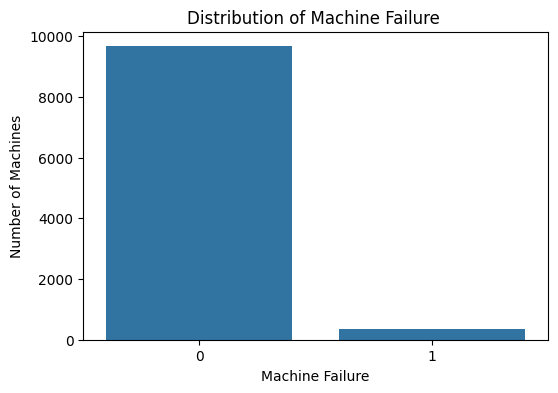

In [17]:
plt.figure(figsize=(6,4))
sns.countplot(x='Machine failure',data=df)
plt.title('Distribution of Machine Failure ')
plt.xlabel('Machine Failure')
plt.ylabel('Number of Machines')
plt.show()

In [18]:
numerical_features = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

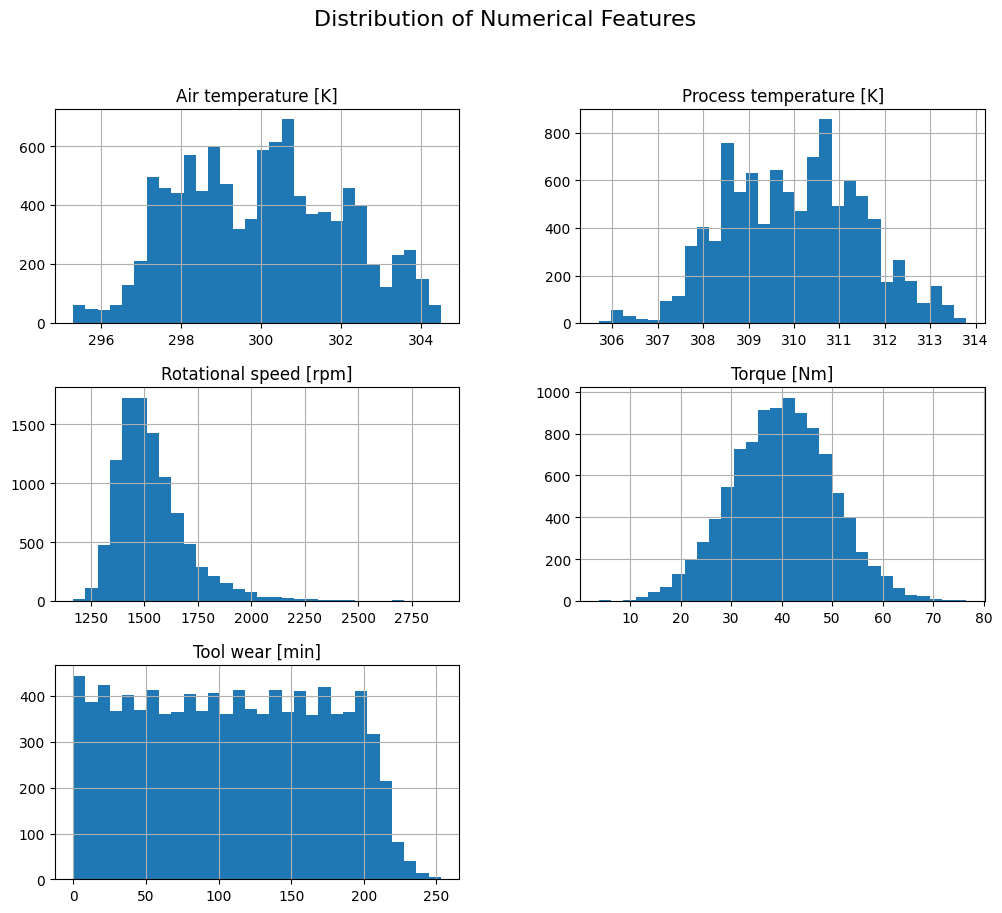

In [19]:
df[numerical_features].hist(bins=30, figsize=(12,10))
plt.suptitle('Distribution of Numerical Features', fontsize=16)
plt.show()

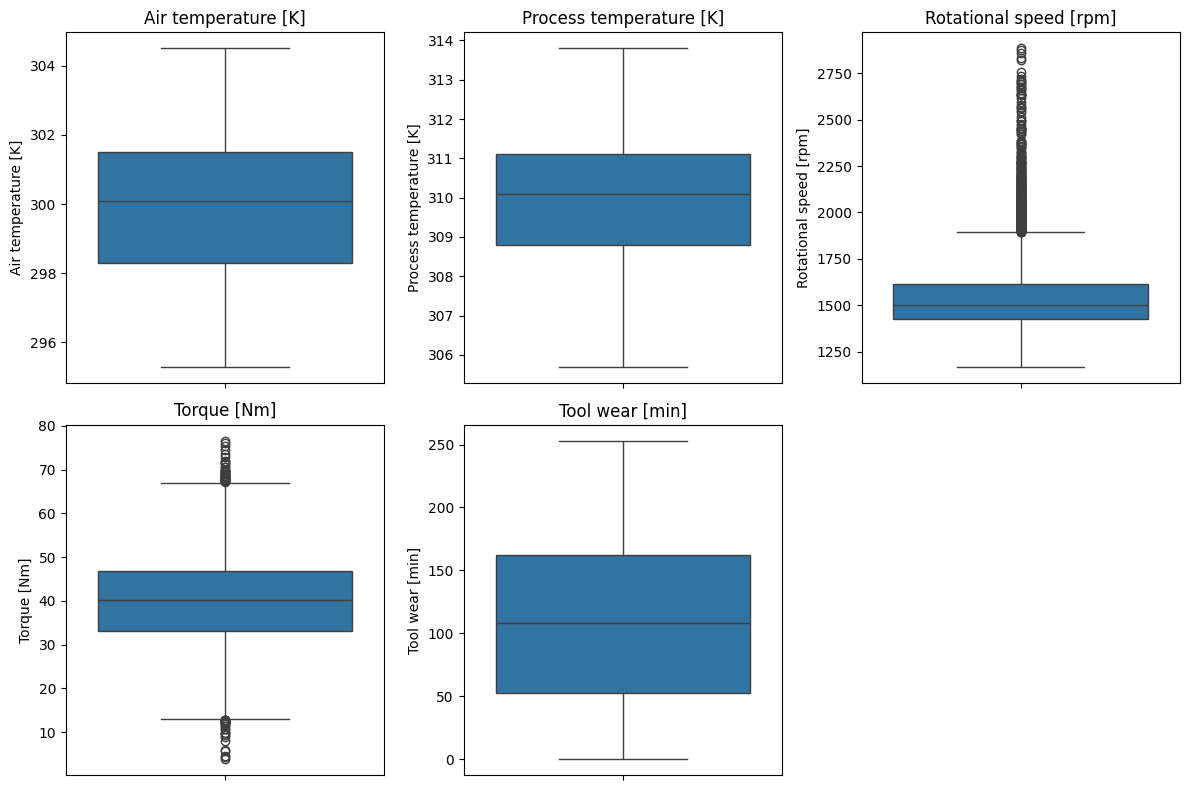

In [21]:
plt.figure(figsize=(12,8))
for i, column in enumerate(numerical_features,1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[column])
    plt.title(column)
plt.tight_layout()
plt.show()  

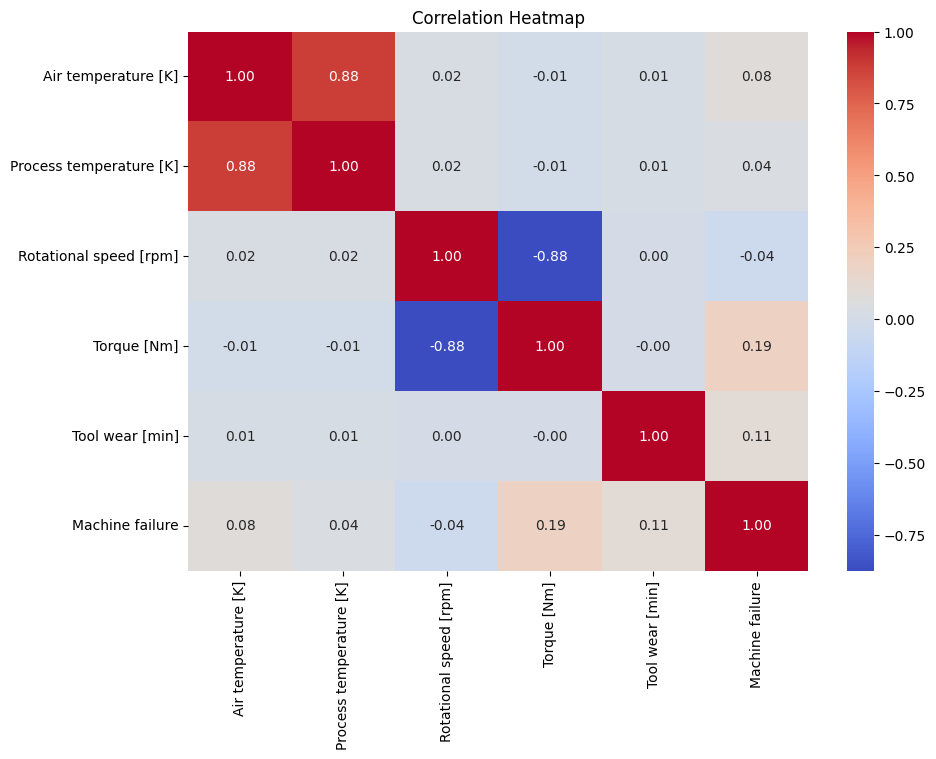

In [24]:
plt.figure(figsize=(10,7))
correlation = df[numerical_features+["Machine failure"]].corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

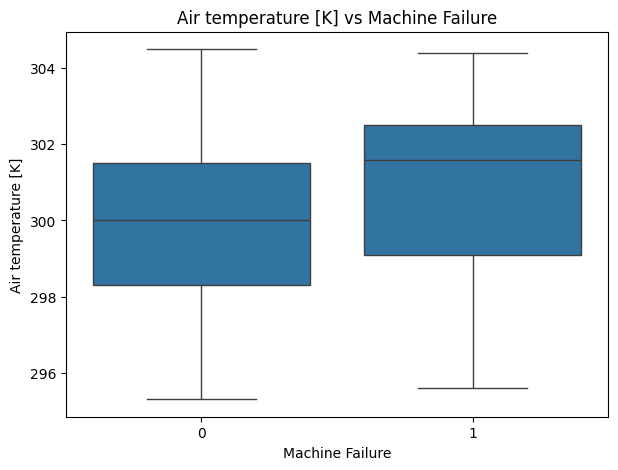

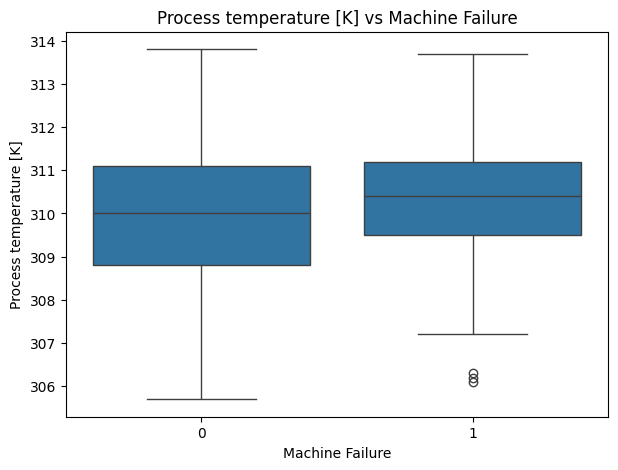

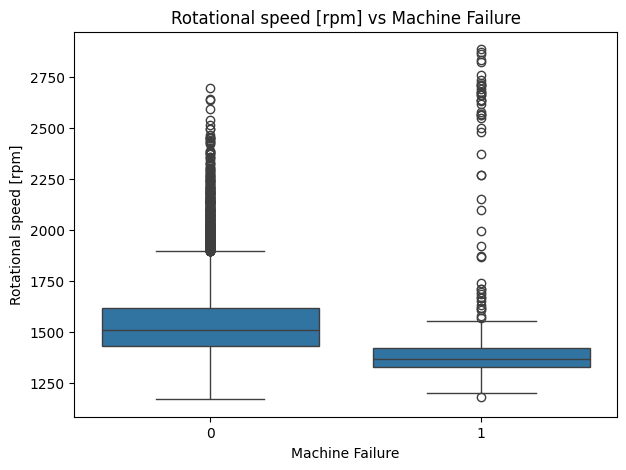

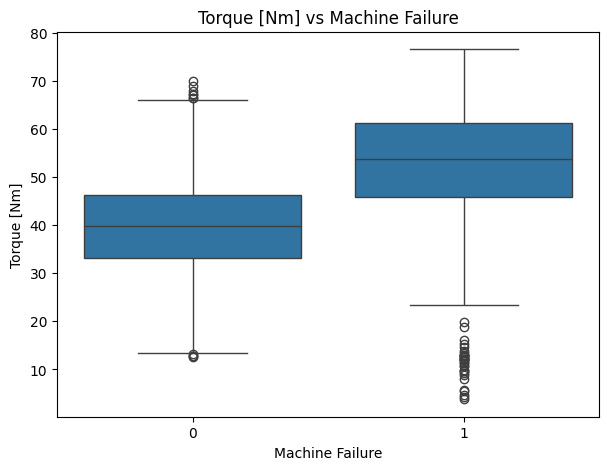

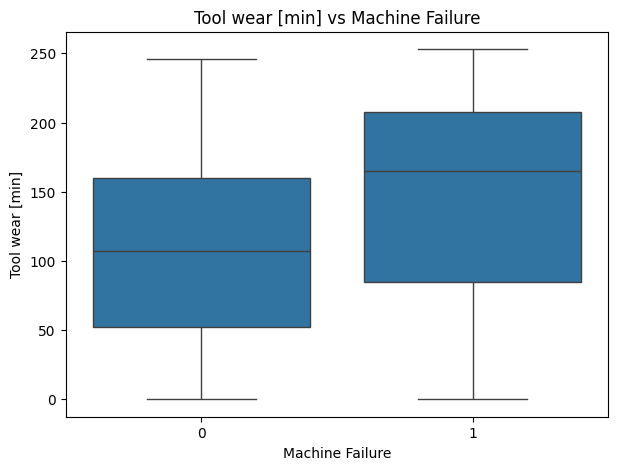

In [25]:
for column in numerical_features:
    plt.figure(figsize=(7,5))
    sns.boxplot(x='Machine failure', y=column, data=df)
    plt.title(f'{column} vs Machine Failure')
    plt.xlabel('Machine Failure')
    plt.ylabel(column)
    plt.show()

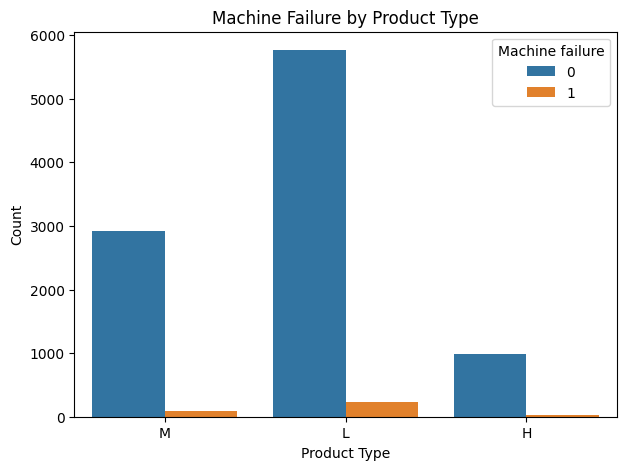

In [26]:
plt.figure(figsize=(7,5))
sns.countplot(x='Type', hue='Machine failure', data=df)
plt.title('Machine Failure by Product Type')
plt.xlabel('Product Type')
plt.ylabel('Count')

plt.show()

In [27]:
X = df[['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type']]

In [28]:
y = df['Machine failure']

In [29]:
print(X.shape, y.shape)

(10000, 6) (10000,)


In [30]:
categorical_features = ['Type']
numerical_features = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training samples:", X_train.shape[0], "Testing samples:", X_test.shape[0])

Training samples: 8000 Testing samples: 2000


In [32]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(), categorical_features)
    ])

In [34]:
linear_svm = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='linear', random_state=42))
])

linear_svm.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [35]:
y_pred_linear = linear_svm.predict(X_test)

In [37]:
accuracy_linear = accuracy_score(y_test, y_pred_linear)
precision_linear = precision_score(y_test, y_pred_linear,zero_division=0)
recall_linear = recall_score(y_test, y_pred_linear,zero_division=0)
F1_linear = f1_score(y_test, y_pred_linear,zero_division=0)

print("Accuracy:", accuracy_linear)
print("Precision:", precision_linear)
print("Recall:", recall_linear)
print("F1 Score:", F1_linear)


Accuracy: 0.966
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [38]:
print(
    classification_report(y_test, y_pred_linear, zero_division=0)
)

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



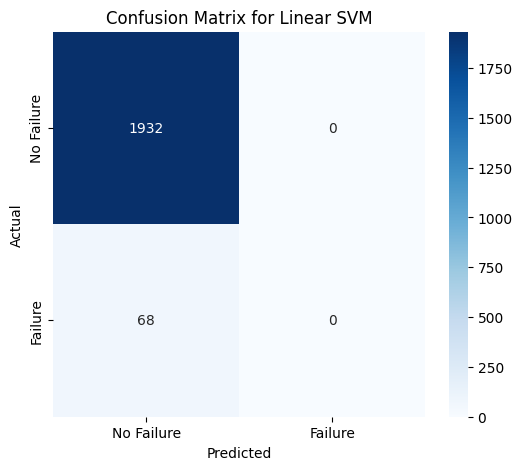

In [39]:
cm_linear = confusion_matrix(y_test, y_pred_linear)
plt.figure(figsize=(6,5))

sns.heatmap(cm_linear, annot=True, fmt='d', cmap='Blues', xticklabels=['No Failure', 'Failure'], yticklabels=['No Failure', 'Failure'])
plt.title('Confusion Matrix for Linear SVM')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()


In [40]:
rbf_svm = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='rbf', random_state=42))
])
rbf_svm.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [41]:
y_pred_rbf = rbf_svm.predict(X_test)

In [43]:
accuracy = accuracy_score(y_test, y_pred_rbf)
precision = precision_score(y_test, y_pred_rbf,zero_division=0)
recall = recall_score(y_test, y_pred_rbf,zero_division=0)
f1 = f1_score(y_test, y_pred_rbf,zero_division=0)
print("Accuracy:", accuracy)
print("Precision:", precision)  
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.972
Precision: 0.875
Recall: 0.20588235294117646
F1 Score: 0.3333333333333333


In [45]:
print(classification_report(y_test, y_pred_rbf,target_names=["No Failure","Failure"], zero_division=0))

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.99      1932
     Failure       0.88      0.21      0.33        68

    accuracy                           0.97      2000
   macro avg       0.92      0.60      0.66      2000
weighted avg       0.97      0.97      0.96      2000



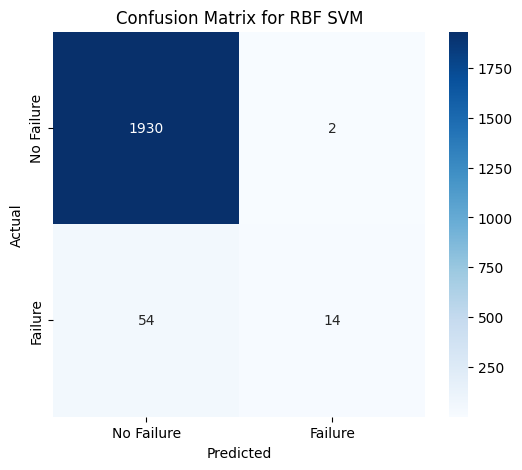

In [46]:
cm_rbf = confusion_matrix(y_test, y_pred_rbf)
plt.figure(figsize=(6,5))
sns.heatmap(cm_rbf, annot=True, fmt='d', cmap='Blues', xticklabels=['No Failure', 'Failure'], yticklabels=['No Failure', 'Failure'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for RBF SVM')
plt.show()

In [52]:
comparison = pd.DataFrame({
    "Kernel": ["Linear", "RBF"],
    "Accuracy": [accuracy_linear, accuracy],
    "Precision": [precision_linear, precision],
    "Recall": [recall_linear, recall],
    "F1 Score": [F1_linear, f1]
})
comparison

,Kernel,Accuracy,Precision,Recall,F1 Score
0,Linear,0.966,0.000,0.000000,0.000000
1,RBF,0.972,0.875,0.205882,0.333333


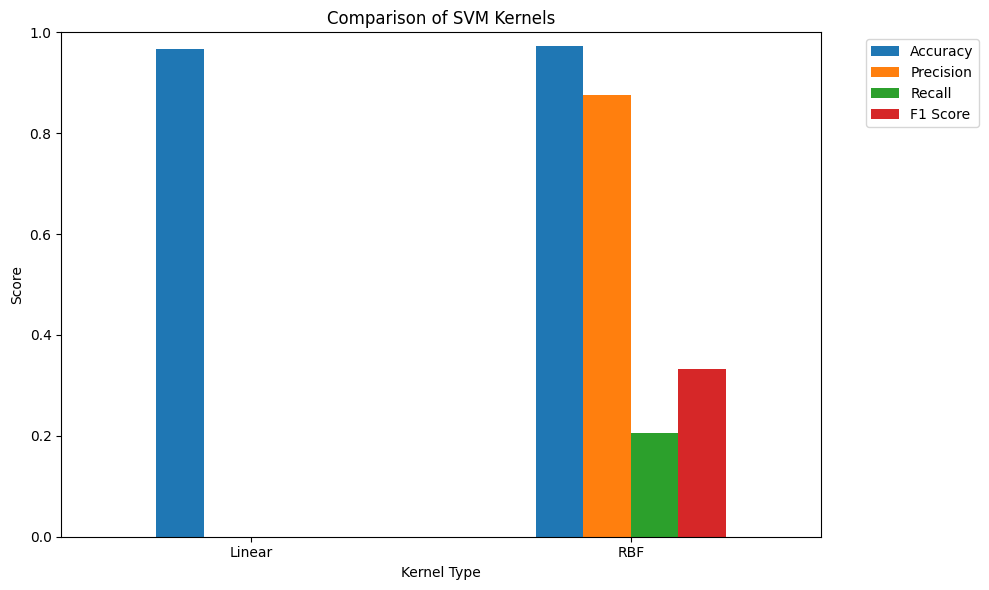

In [53]:
comparison_plot = comparison.set_index('Kernel')
comparison_plot.plot(kind='bar', figsize=(10,6))

plt.title('Comparison of SVM Kernels')
plt.xlabel('Kernel Type')
plt.ylabel('Score')
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [54]:
from sklearn.pipeline import Pipeline
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='rbf', random_state=42))])

In [58]:
param_grid = [{
    "classifier__kernel": ["linear"],
    "classifier__C": [0.1, 1, 10, 100]
}, {
    "classifier__kernel": ["rbf"],
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__gamma": ['scale', 0.01, 0.1, 1]
}]

In [59]:
grid_search = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=5, scoring='f1', n_jobs=-1,verbose=1)

In [60]:
grid_search.fit(X_train, y_train)
print("GridSearchCV completed.")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
GridSearchCV completed.


In [61]:
print("Best parameters found: ", grid_search.best_params_)

Best parameters found:  {'classifier__C': 100, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}


In [62]:
print("Best Cross-Validation F1 Score: ", grid_search.best_score_)

Best Cross-Validation F1 Score:  0.7080372186703207


In [63]:
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)

In [64]:
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned, zero_division=0)
recall_tuned = recall_score(y_test, y_pred_tuned, zero_division=0)
f1_tuned = f1_score(y_test, y_pred_tuned, zero_division=0)
print("Tuned Model Performance:")
print("Accuracy:", accuracy_tuned)
print("Precision:", precision_tuned)
print("Recall:", recall_tuned)
print("F1 Score:", f1_tuned)

Tuned Model Performance:
Accuracy: 0.98
Precision: 0.7592592592592593
Recall: 0.6029411764705882
F1 Score: 0.6721311475409836


In [66]:
final_comparison = pd.DataFrame({
    "Model": ["Linear SVM", "RBF SVM", "Tuned SVM"],
    "Accuracy": [accuracy_linear, accuracy, accuracy_tuned],
    "Precision": [precision_linear, precision, precision_tuned],
    "Recall": [recall_linear, recall, recall_tuned],
    "F1 Score": [F1_linear, f1, f1_tuned]
})
final_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.966,0.000000,0.000000,0.000000
1,RBF SVM,0.972,0.875000,0.205882,0.333333
2,Tuned SVM,0.980,0.759259,0.602941,0.672131


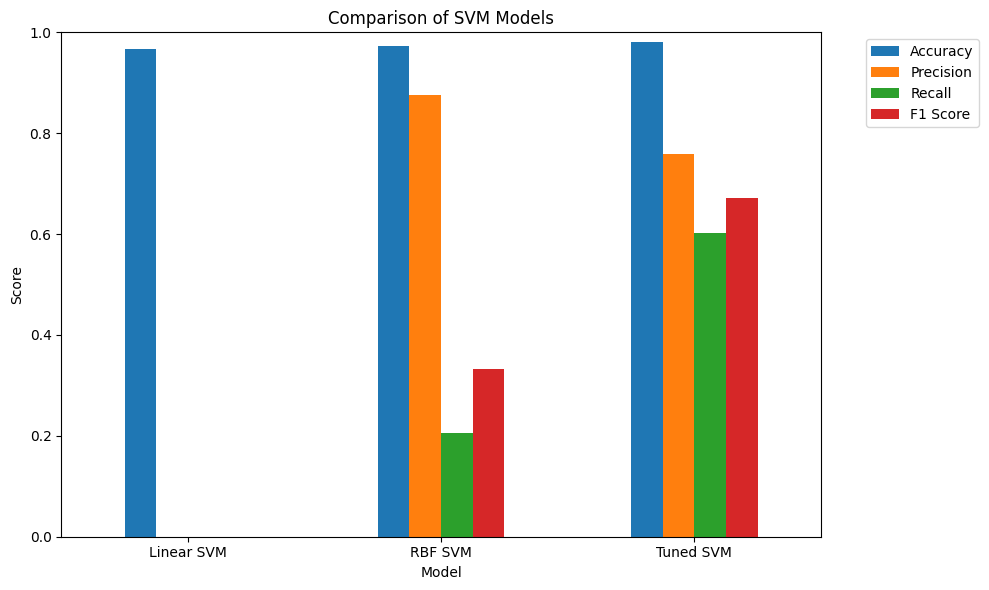

In [67]:
final_comparison_plot = final_comparison.set_index('Model')
final_comparison_plot.plot(kind='bar', figsize=(10,6))

plt.title('Comparison of SVM Models')
plt.xlabel('Model')
plt.ylabel('Score')
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()